# TRUCS : Décomposer un signal

Sans être dépendant de librairies obscure et chères !


In [63]:
clear all;
close all;
graphics_toolkit ("gnuplot"); %% A exécuter uniquement pour les Notebooks Octave, pas pour Octave ni Matlab ni python

# A -  Solution à deux vecteurs réels

Il suffit de créer la base des vecteurs de décomposition $\vec{w_n}$ et de décomposer avec le produit scalaire et de voir ce qui reste. 

L'astuce est d'empiler les vecteurs de la base dans une matrice pour avoir en un seul produit matriciel toutes les décompositions...

On définit deux signaux de base dans l'espace de signaux 6 périodiques : 

   - $w_0$ le signal constant
   - $w_1$ le signal carré qui vaut [1 1 1  -1 -1 -1]

Et un signal $s$ à décomposer tiré au hasard 

In [64]:
k = 1:6;
w0 = cos(k*0) % astuce la constant est la fréquence nulle
w1 = [1 1 1 -1 -1 -1]

s = round(rand(1,6)*10-5)

w0 =

   1   1   1   1   1   1

w1 =

   1   1   1  -1  -1  -1

s =

   1   2  -2   2  -4   0



On aimerait avoir la décomposition 

$s = c_0.w_0 + c_1.w_1 + \epsilon$ 

avec le epsilon le plus petit possible.

Avec un produit scalaire, cette décomposition devient une projection dans le plan $(w_0, w_1)$ avec un epsilon le plus petit possible au sens du produit scalaire :

$<\epsilon,\epsilon> = \|\epsilon\|^2 $ minimal.

Calculons ces produits scalaires :

In [72]:
M = [w0 ; w1] % première ligne w0 et deuxième ligne w1
norm_w0_carre = w0*w0'
norm_w1_carre = w1*w1'

scalaires = M*s'

M =

   1   1   1   1   1   1
   1   1   1  -1  -1  -1

norm_w0_carre = 6
norm_w1_carre = 6
scalaires =

  -1
   3



Si on calcule le scalaire $<\vec{s},\vec{w_0}>$ et que l'on a $\vec{s}= c_0.\vec{w_0} + c_1.\vec{w_1} + \vec{\epsilon}$ on obtient

$<\vec{s},\vec{w_0}> = < c_0.\vec{w_0} + c_1.\vec{w_1} + \vec{\epsilon}\quad ,\quad \vec{w_0}>$

$<\vec{s},\vec{w_0}> = c_0\;.\;\underbrace{< \vec{w_0} , \vec{w_0}>}_{\|\vec{w_0}\|^2} \quad+\quad c_1 \;.\;\underbrace{< \vec{w_1} , \vec{w_0}>}_{=0 \text{ car orthogonal}} \quad+\quad \underbrace{<\vec{\epsilon} , \vec{w_0}>}_{=0\text{ car reste orthogonal}}$

Cela permet de trouver le coefficient de la composante $\vec{w_0}$ :

$c_0 = \frac{<\vec{s},\vec{w_0}>}{<\vec{w_0},\vec{w_0}>}= \frac{<\vec{s},\vec{w_0}>}{\|w_0\|^2}$

Calculons les coefficients et reconstruisons le signal $s_r$ composé de $w_0$ et $w_1$ qui est le plus proche de $s$ au sens des moindre carrés :

$\vec{s_r} = c_0 . \vec{w_0} + c_1. \vec{w_1} $  avec 

$\vec{s}= \underbrace{\vec{s_r}}_{\text{dans le plan } (w_0, w_1)} + \underbrace{\vec{\epsilon}}_{\text{orthogonal au plan}}$


In [73]:
produits_wi_wj = M*M' 
disp("les diagonales sont les normes au carré et en dehors <w_i,w_j>=0 car base orthogonale")

c = inv(M*M')*M*s'


sr = c'*M


produits_wi_wj =

   6   0
   0   6

les diagonales sont les normes au carré et en dehors <w_i,w_j>=0 car base orthogonale
c =

  -0.1667
   0.5000

sr =

   0.3333   0.3333   0.3333  -0.6667  -0.6667  -0.6667



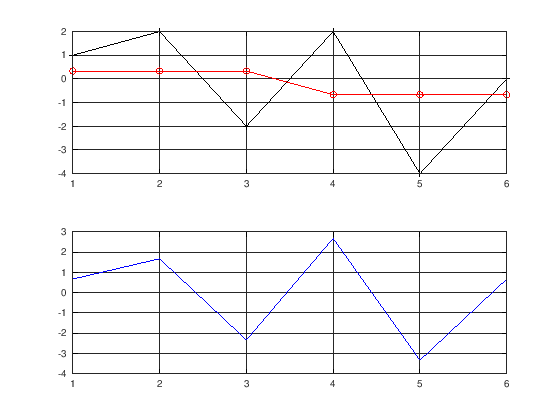

In [79]:
subplot(211);
title("Signal et sa décomposition la plus proche")
plot(k,s,'k-+');
hold on;
plot(k,sr,'r-o');
grid on;
subplot(212);
title("Erreur la plus petite aux moindres carrés")
plot(k,s-sr,'b-');
grid on;
